<a href="https://colab.research.google.com/github/sidhu2690/HydroGraphNet/blob/main/White_River_M80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!git clone https://github.com/sidhu2690/HydroGraphNet.git
%cd HydroGraphNet

Cloning into 'HydroGraphNet'...
remote: Enumerating objects: 70, done.
remote: Counting objects: 100% (70/70), done.
remote: Compressing objects: 100% (67/67), done.
remote: Total 70 (delta 11), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (70/70), 21.79 MiB | 11.74 MiB/s, done.
Resolving deltas: 100% (11/11), done.
/content/HydroGraphNet


In [3]:
!python scripts/download_data.py \
    --data_dir ./data_sample \
    --num_train 6 \
    --num_test 3

Opening remote archive https://zenodo.org/api/records/15491288/files/HydroGraphNet.zip/content via HTTP Range...
Fetching 60 files (6 train runs: ['H1', 'H2', 'H3', 'H4', 'H5', 'H6'], 3 test runs: ['T1', 'T2', 'T3'])...
[DONE] Subset ready in data_sample


In [4]:
import os

DATA_DIR = "./data_sample"

for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        path = os.path.join(root, file)
        size = os.path.getsize(path) / (1024**2)
        print(f"{indent}    {file} ({size:.2f} MB)")

data_sample/
    M80_US_InF_H1.txt (0.01 MB)
    M80_Pr_H5.txt (0.00 MB)
    M80_V_H2.txt (13.83 MB)
    M80_V_H4.txt (13.71 MB)
    M80_US_InF_H5.txt (0.01 MB)
    M80_Pr_H1.txt (0.00 MB)
    M80_Pr_H3.txt (0.00 MB)
    static_norm_stats.json (0.00 MB)
    M80_WD_H1.txt (12.62 MB)
    M80_WD_H5.txt (12.62 MB)
    M80_CS.txt (0.04 MB)
    M80_US_InF_H6.txt (0.01 MB)
    M80_Pr_H4.txt (0.00 MB)
    M80_V_H6.txt (13.70 MB)
    M80_Pr_H2.txt (0.00 MB)
    M80_FA.txt (0.02 MB)
    M80_N.txt (0.06 MB)
    M80_XY.txt (0.16 MB)
    M80_CA.txt (0.08 MB)
    M80_CU.txt (0.03 MB)
    M80_US_InF_H4.txt (0.01 MB)
    M80_WD_H6.txt (12.62 MB)
    M80_IP.txt (0.02 MB)
    M80_US_InF_H3.txt (0.01 MB)
    M80_WD_H2.txt (12.62 MB)
    M80_WD_H4.txt (12.62 MB)
    dynamic_norm_stats.json (0.00 MB)
    M80_WD_H3.txt (12.62 MB)
    M80_A.txt (0.03 MB)
    M80_V_H5.txt (13.73 MB)
    M80_US_InF_H2.txt (0.01 MB)
    M80_CE.txt (0.07 MB)
    M80_V_H3.txt (13.74 MB)
    train.txt (0.00 MB)
    M80_Pr_H6.txt (

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

prefix = "M80"

static_variables = {
    "XY": "Coordinates",
    "CA": "Cell area",
    "CE": "Elevation",
    "CS": "Slope",
    "A": "Aspect",
    "CU": "Curvature",
    "N": "Manning roughness",
    "FA": "Flow accumulation",
    "IP": "IP"
}

static = {}

for key, description in static_variables.items():

    path = f"{DATA_DIR}/{prefix}_{key}.txt"

    arr = np.loadtxt(path)

    static[key] = arr

    print(f"\n{description}")
    print("Shape:", arr.shape)
    print("Min:", np.nanmin(arr))
    print("Max:", np.nanmax(arr))
    print("Mean:", np.nanmean(arr))
    print("Std:", np.nanstd(arr))


Coordinates
Shape: (4787, 2)
Min: 404485.103963422
Max: 1805688.78740403
Mean: 1105734.8605730834
Std: 697231.3791234605

Cell area
Shape: (5081,)
Min: 0.0
Max: 13287.952148438
Mean: 5828.4333295245915
Std: 1688.5529890557134

Elevation
Shape: (5081,)
Min: 277.953216553
Max: 293.651672363
Mean: 286.0327602344224
Std: 2.354108503453698

Slope
Shape: (4787,)
Min: 0.0
Max: 52.1980095
Mean: 1.903820562043033
Std: 3.004354773991102

Aspect
Shape: (4787,)
Min: -1.0
Max: 358.0250549
Mean: 109.19389937781492
Std: 121.34381945101399

Curvature
Shape: (4787,)
Min: -31.885498
Max: 30.8603516
Mean: -0.02829149678295383
Std: 1.5491148967915929

Manning roughness
Shape: (5081,)
Min: 0.029999999
Max: 0.200000003
Mean: 0.08321983904841566
Std: 0.05225259237218659

Flow accumulation
Shape: (4787,)
Min: 0.0
Max: 37845.0
Mean: 83.51410068936704
Std: 928.2786507037933

IP
Shape: (4787,)
Min: 0.0
Max: 90.0
Mean: 39.07144349279298
Std: 28.144140786439884


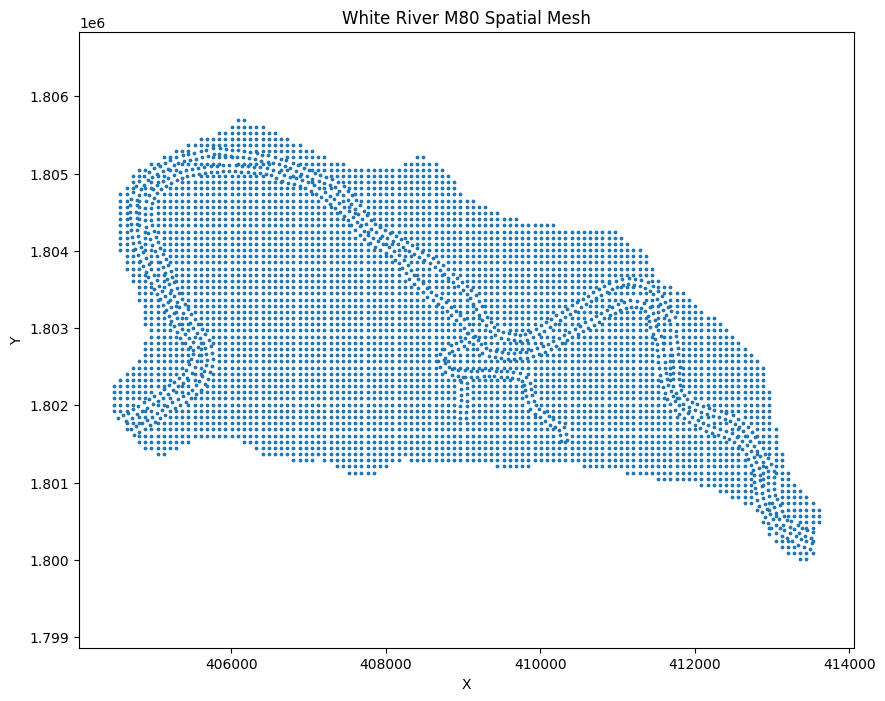

In [15]:
xy = static["XY"]

plt.figure(figsize=(10, 8))
plt.scatter(xy[:, 0], xy[:, 1], s=3)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("White River M80 Spatial Mesh")
plt.axis("equal")
plt.show()

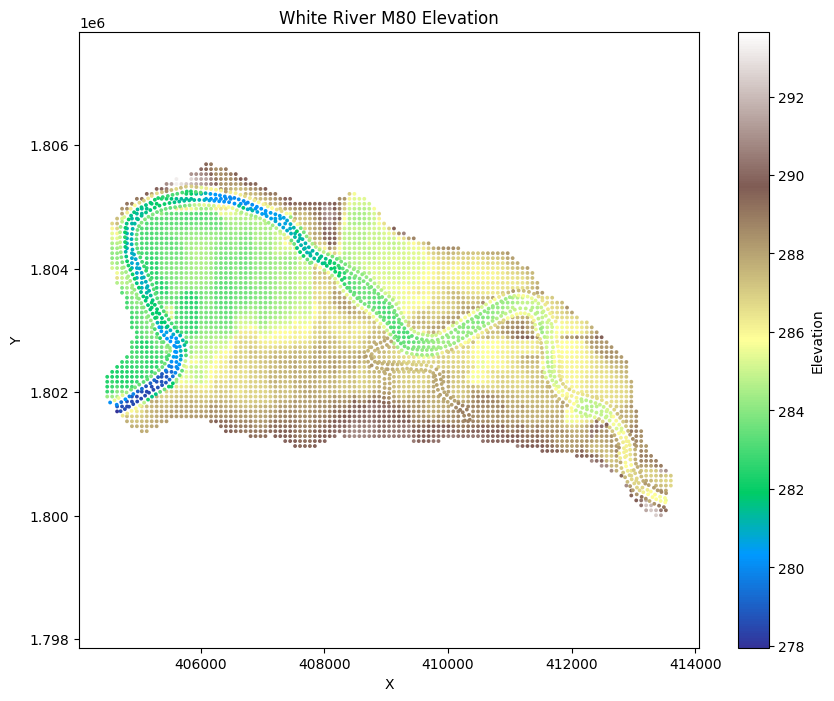

In [16]:
ce = static["CE"]

plt.figure(figsize=(10, 8))
plt.scatter(xy[:, 0], xy[:, 1], c=ce, s=3, cmap="terrain")
plt.colorbar(label="Elevation")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("White River M80 Elevation")
plt.axis("equal")
plt.show()

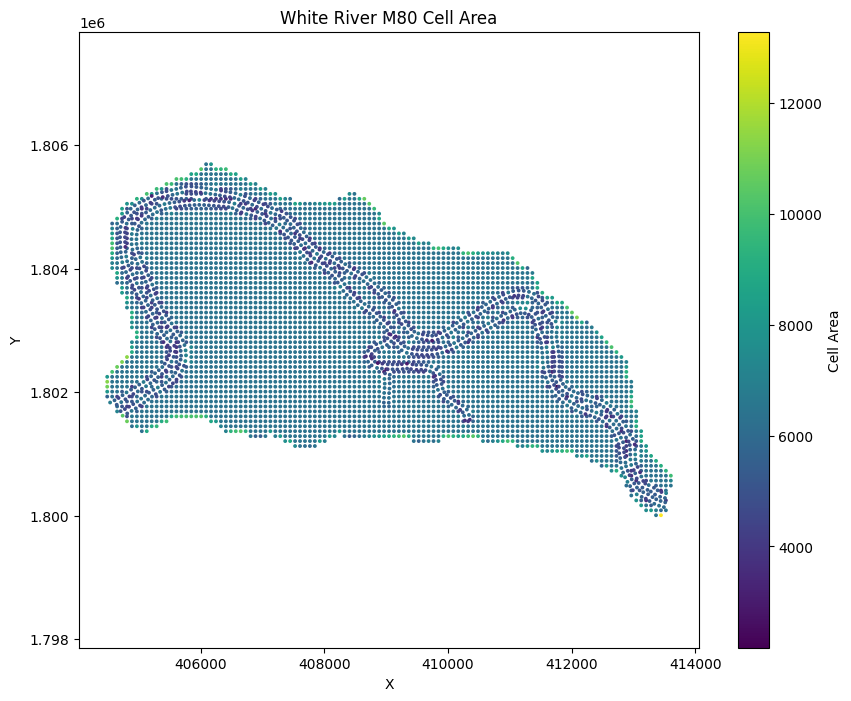

In [17]:
ca = static["CA"]

plt.figure(figsize=(10, 8))
plt.scatter(xy[:, 0], xy[:, 1], c=ca, s=3, cmap="viridis")
plt.colorbar(label="Cell Area")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("White River M80 Cell Area")
plt.axis("equal")
plt.show()

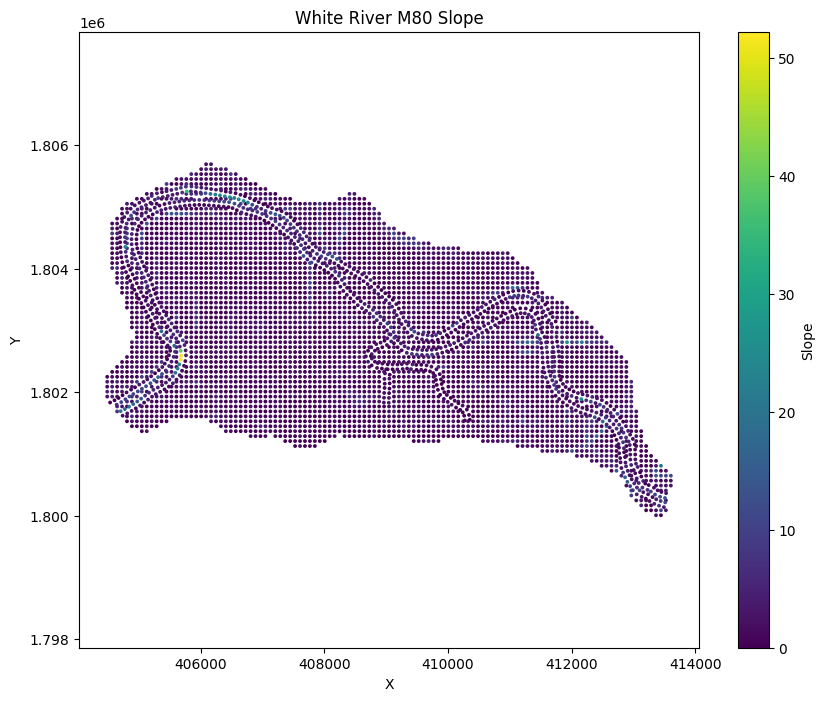

In [18]:
cs = static["CS"]

plt.figure(figsize=(10, 8))
plt.scatter(xy[:, 0], xy[:, 1], c=cs, s=3, cmap="viridis")
plt.colorbar(label="Slope")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("White River M80 Slope")
plt.axis("equal")
plt.show()

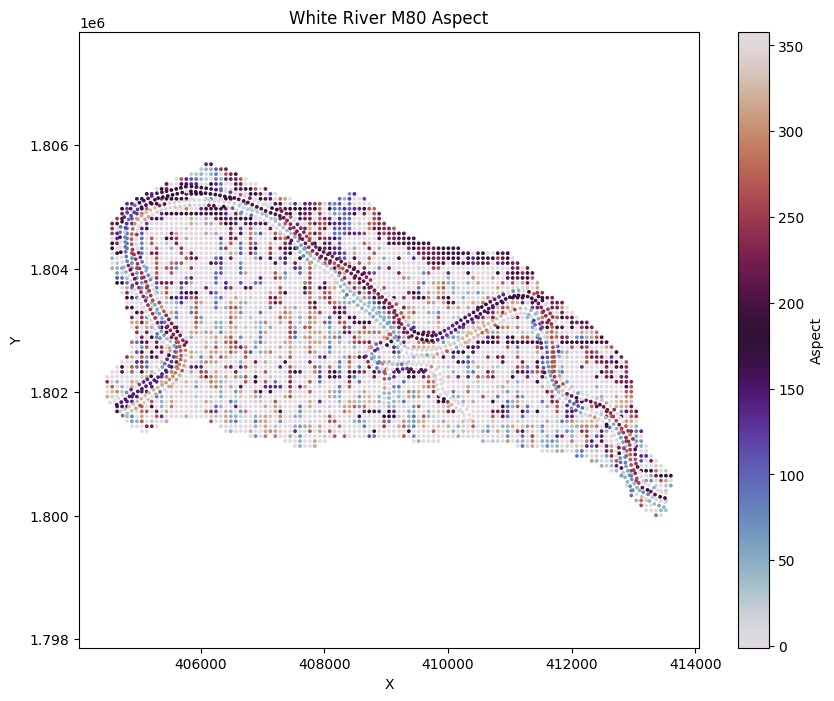

In [19]:
a = static["A"]

plt.figure(figsize=(10, 8))
plt.scatter(xy[:, 0], xy[:, 1], c=a, s=3, cmap="twilight")
plt.colorbar(label="Aspect")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("White River M80 Aspect")
plt.axis("equal")
plt.show()

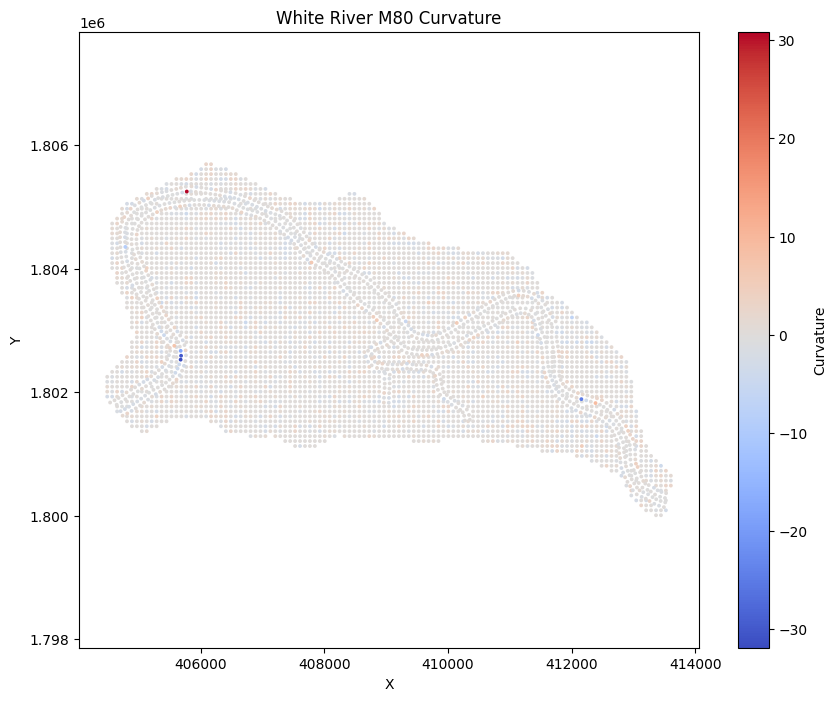

In [20]:
cu = static["CU"]

plt.figure(figsize=(10, 8))
plt.scatter(xy[:, 0], xy[:, 1], c=cu, s=3, cmap="coolwarm")
plt.colorbar(label="Curvature")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("White River M80 Curvature")
plt.axis("equal")
plt.show()

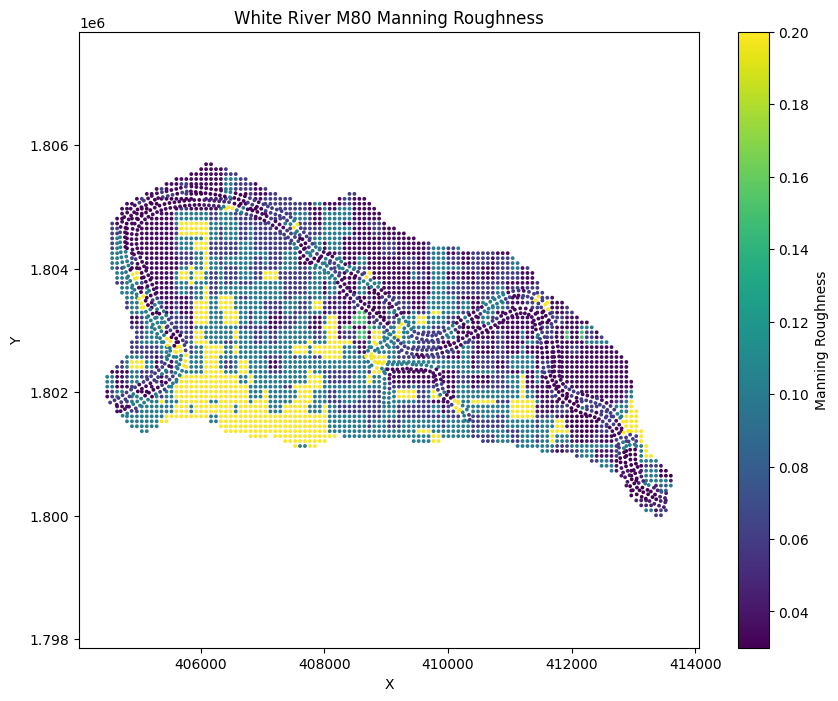

In [21]:
n = static["N"]

plt.figure(figsize=(10, 8))
plt.scatter(xy[:, 0], xy[:, 1], c=n, s=3, cmap="viridis")
plt.colorbar(label="Manning Roughness")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("White River M80 Manning Roughness")
plt.axis("equal")
plt.show()

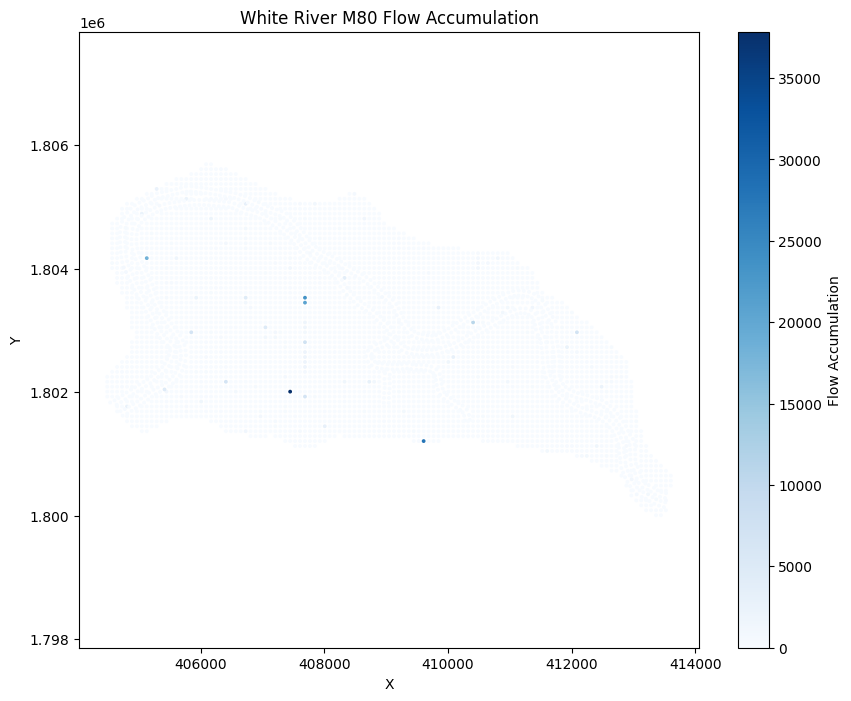

In [22]:
fa = static["FA"]

plt.figure(figsize=(10, 8))
plt.scatter(xy[:, 0], xy[:, 1], c=fa, s=3, cmap="Blues")
plt.colorbar(label="Flow Accumulation")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("White River M80 Flow Accumulation")
plt.axis("equal")
plt.show()

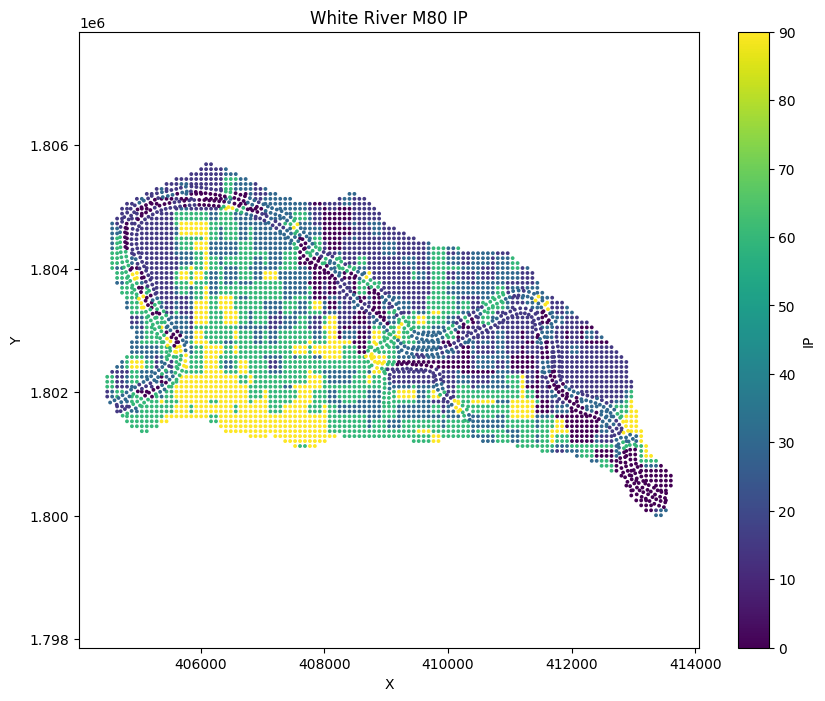

In [23]:
ip = static["IP"]

plt.figure(figsize=(10, 8))
plt.scatter(xy[:, 0], xy[:, 1], c=ip, s=3, cmap="viridis")
plt.colorbar(label="IP")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("White River M80 IP")
plt.axis("equal")
plt.show()